# DSA4262 • Explore and clean m6A training data

## Goal
Turn the handout's **read-level JSON** into an audited **site-level feature table** for exploratory analysis and tabular models. One observation is `(transcript_id, transcript_position)`; one site contains multiple reads, each with nine measurements.

**Source:** `handout_project2_RNAModifications.html`, sections “Format description” and “Training data”. Labels come from `data.info`; join using **both** transcript ID and position. No coordinate offsets or transcript-version stripping are applied.

**Status:** Prepared from the handout; your real dataset is not included and has not been analysed here. Run the cells in order on the machine holding your files. This notebook does not train models or replace the required training/prediction scripts.

## Setup
1. Save this notebook in your repository, for example `notebooks/`.
2. Select your Python virtual-environment kernel in VS Code connected to Ronin.
3. Set the two absolute input paths below. Run all cells from top to bottom.
4. Start with 5,000 lines to check the format; then set `MAX_LINES = None` and rerun for the full dataset. A prefix is **not** a representative random sample.

Raw input files are read only. Outputs go to a new timestamped folder. Keep raw data and generated outputs out of GitHub; commit this notebook and your code.

In [3]:
# Uncomment once if packages are missing, then restart the kernel.
# %pip install numpy pandas matplotlib scikit-learn ipykernel
from pathlib import Path
from datetime import datetime, timezone
import json, gzip, re, sys, platform, hashlib, importlib.metadata
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 12)

Matplotlib is building the font cache; this may take a moment.


### 1. Set paths and cleaning choices
`MIN_VALID_READS = 1` retains every site with at least one usable read. This is an exploration default, **not** a scientifically established coverage threshold. Review coverage before selecting a modelling threshold.

A valid read has nine finite numbers, nonnegative dwell times, and nonnegative signal standard deviations. Signal means are only checked for finiteness. Extreme finite values are retained; no arbitrary clipping, scaling, imputation, or class resampling is performed.

In [11]:
DATA_JSON = Path(r"D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\dataset\data0\dataset0.json\dataset0.json")  # .json.gz also supported
LABELS_FILE = Path(r"D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\dataset\data0\data.info.labelled")  # CSV, optionally .gz
OUTPUT_ROOT = Path.cwd() / 'outputs' / 'm6a_eda'
MAX_LINES = None  # None for the full file; includes blank lines in the limit
MIN_VALID_READS = 1
MAKE_SPLITS = False  # set True after reviewing full-data QC
SEED = 42

assert MIN_VALID_READS >= 1
assert MAX_LINES is None or MAX_LINES > 0
for p in (DATA_JSON, LABELS_FILE):
    if not p.is_file():
        raise FileNotFoundError(f'Edit the path in this cell: {p}')
RUN_DIR = OUTPUT_ROOT / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
RUN_DIR.mkdir(parents=True, exist_ok=False)
print('Outputs:', RUN_DIR)
print('Mode:', 'FULL FILE' if MAX_LINES is None else f'FIRST {MAX_LINES:,} LINES ONLY')
display(pd.DataFrame([{'file': str(p), 'size_GiB': p.stat().st_size / 2**30}
                      for p in (DATA_JSON, LABELS_FILE)]))

Outputs: d:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\DSA4262-datahelix\data_cleaning\outputs\m6a_eda\20261005T115003_741688Z
Mode: FULL FILE


,file,size_GiB
0,D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_ge...,0.582484
1,D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_ge...,0.004379


### 2. Feature meaning
The nine columns in each read are ordered as follows. A seven-base sequence such as `AAGACCA` contains three overlapping five-mers: `AAGAC`, `AGACC`, `GACCA`. The central five-mer is `sequence[1:6]`; its central A is `sequence[3]`.

We summarise each measurement across valid reads using mean, population standard deviation (`ddof=0`), median, 25th percentile, and 75th percentile. These summaries support tabular baselines but lose read-level dependencies needed by multiple-instance learning. The raw JSON remains your source for those models.

In [12]:
SIGNALS = [f'{location}_{measure}'
           for location in ('minus1', 'center', 'plus1')
           for measure in ('dwell', 'signal_sd', 'signal_mean')]
STATS = ('mean', 'std', 'median', 'q25', 'q75')
FEATURES = [f'{name}_{stat}' for stat in STATS for name in SIGNALS]
KEY = ['transcript_id', 'transcript_position']
display(pd.DataFrame({'index': range(9), 'measurement': SIGNALS}))

,index,measurement
0,0,minus1_dwell
1,1,minus1_signal_sd
2,2,minus1_signal_mean
3,3,center_dwell
4,4,center_signal_sd
5,5,center_signal_mean
6,6,plus1_dwell
7,7,plus1_signal_sd
8,8,plus1_signal_mean


### 3. Parse one line at a time and audit problems
This avoids loading the entire read-level file into memory. Site summaries still consume memory proportional to the number of sites.

Malformed JSON or an ambiguous schema stops with a line number rather than silently losing sites. Duplicate JSON keys also stop parsing. Invalid reads are excluded and counted. Sites with invalid sequences, a non-DRACH centre, or insufficient valid reads are quarantined later. These are explicit choices based on the handout's expected format.

Repeated site keys are quarantined in **all** occurrences, not merged: without read identifiers, merging could double-count reads. Identical read vectors within a site are counted for review but retained because distinct reads can have the same measurements.

In [13]:
def open_text(path):
    return gzip.open(path, 'rt', encoding='utf-8') if path.suffix == '.gz' else path.open(encoding='utf-8')

def unique_object(pairs):
    result = {}
    for k, v in pairs:
        if k in result:
            raise ValueError(f'Duplicate JSON key: {k!r}')
        result[k] = v
    return result

def read_matrix(reads):
    if not isinstance(reads, list):
        raise ValueError('Expected a list of reads')
    valid, reasons = [], Counter()
    for read in reads:
        if not isinstance(read, list) or len(read) != 9:
            reasons['wrong_length'] += 1; continue
        if any(isinstance(v, bool) or not isinstance(v, (int, float)) for v in read):
            reasons['nonnumeric'] += 1; continue
        a = np.asarray(read, dtype=float)
        if not np.isfinite(a).all():
            reasons['nonfinite'] += 1; continue
        if (a[[0, 1, 3, 4, 6, 7]] < 0).any():
            reasons['negative_dwell_or_sd'] += 1; continue
        valid.append(a)
    return np.asarray(valid, dtype=float).reshape(-1, 9), reasons

def parse_sites(path, max_lines=None):
    records, totals = [], Counter()
    with open_text(path) as handle:
        for line_no, line in enumerate(handle, 1):
            if max_lines is not None and line_no > max_lines: break
            totals['lines_scanned'] += 1
            if not line.strip():
                totals['blank_lines'] += 1; continue
            try:
                obj = json.loads(line, object_pairs_hook=unique_object)
                if not isinstance(obj, dict) or len(obj) != 1:
                    raise ValueError('Expected exactly one transcript per line')
                transcript, positions = next(iter(obj.items()))
                if not transcript.strip() or not isinstance(positions, dict) or len(positions) != 1:
                    raise ValueError('Expected one position and a nonempty transcript ID')
                pos, sequences = next(iter(positions.items()))
                if not re.fullmatch(r'\d+', pos):
                    raise ValueError('Position must be a nonnegative integer string')
                if not isinstance(sequences, dict) or len(sequences) != 1:
                    raise ValueError('Expected exactly one sequence per site')
                sequence, reads = next(iter(sequences.items()))
                a, reasons = read_matrix(reads)
                row = {'transcript_id': transcript, 'transcript_position': int(pos),
                       'sequence': sequence, 'central_5mer': sequence[1:6],
                       'source_line': line_no, 'n_reads_raw': len(reads),
                       'n_reads_valid': len(a), 'n_reads_removed': len(reads)-len(a),
                       'valid_sequence': bool(re.fullmatch('[ACGT]{7}', sequence)),
                       'is_drach': bool(re.fullmatch('[AGT][AG]AC[ACT]', sequence[1:6])),
                       'n_identical_vectors': len(a)-len(np.unique(a, axis=0))}
                for reason in ('wrong_length','nonnumeric','nonfinite','negative_dwell_or_sd'):
                    row['removed_'+reason] = reasons[reason]
                values = ([a.mean(0), a.std(0), np.median(a, axis=0),
                           np.quantile(a, .25, axis=0), np.quantile(a, .75, axis=0)]
                          if len(a) else [np.full(9, np.nan)]*5)
                row.update({f'{name}_{stat}': float(v)
                            for stat, arr in zip(STATS, values)
                            for name, v in zip(SIGNALS, arr)})
                records.append(row)
            except (ValueError, TypeError, OverflowError) as exc:
                raise ValueError(f'Cannot parse line {line_no}: {exc}') from exc
            if line_no % 10000 == 0: print(f'Parsed {line_no:,} lines')
    if not records: raise ValueError('No site records found')
    return pd.DataFrame(records), dict(totals)

sites, parse_counts = parse_sites(DATA_JSON, MAX_LINES)
print(parse_counts)
display(sites.head(3))

Parsed 10,000 lines
Parsed 20,000 lines
Parsed 30,000 lines
Parsed 40,000 lines
Parsed 50,000 lines
Parsed 60,000 lines
Parsed 70,000 lines
Parsed 80,000 lines
Parsed 90,000 lines
Parsed 100,000 lines
Parsed 110,000 lines
Parsed 120,000 lines
{'lines_scanned': 121838}


,transcript_id,transcript_position,sequence,central_5mer,source_line,n_reads_raw,...,center_dwell_q75,center_signal_sd_q75,center_signal_mean_q75,plus1_dwell_q75,plus1_signal_sd_q75,plus1_signal_mean_q75
0,ENST00000000233,244,AAGACCA,AGACC,1,185,...,0.012600,10.20,128.0,0.009960,5.68,82.000
1,ENST00000000233,261,CAAACTG,AAACT,2,172,...,0.008303,3.67,110.0,0.009458,3.49,95.725
2,ENST00000000233,316,GAAACAG,AAACA,3,185,...,0.009300,4.25,101.0,0.008960,2.44,90.100


### 4. Clean labels without changing coordinate conventions
Only exact duplicate label rows are collapsed. Missing/invalid keys, labels other than 0/1, and all conflicting rows for a site are excluded from training and exported for review. A missing label is **not** an unmodified (0) label. Missing gene IDs may remain usable for exploration but cannot be used in the gene-based split.

In [14]:
labels_raw = pd.read_csv(LABELS_FILE, dtype=str, keep_default_na=False)
required = {'gene_id', 'transcript_id', 'transcript_position', 'label'}
if not required.issubset(labels_raw.columns):
    raise ValueError(f'Expected label columns {required}; found {list(labels_raw.columns)}')
labels = labels_raw[sorted(required)].copy()
labels['source_label_row'] = np.arange(len(labels)) + 2
p = labels['transcript_position']
valid_pos = p.str.fullmatch(r'\d+') & p.map(lambda x: len(x) < 19)
valid_label = labels['label'].isin(['0', '1'])
valid_id = labels['transcript_id'].str.strip().ne('')
bad_label_rows = labels.loc[~(valid_pos & valid_label & valid_id)].copy()
labels = labels.loc[valid_pos & valid_label & valid_id].copy()
labels['transcript_position'] = labels['transcript_position'].astype('int64')
labels['label'] = labels['label'].astype('int8')
exact_duplicates = labels.duplicated(sorted(required))
n_exact_label_duplicates = int(exact_duplicates.sum())
labels = labels.loc[~exact_duplicates].copy()
conflict_mask = labels.duplicated(KEY, keep=False)
conflicting_labels = labels.loc[conflict_mask].copy()
labels = labels.loc[~conflict_mask].drop(columns='source_label_row')
labels['gene_id'] = labels['gene_id'].replace('', pd.NA)
print({'raw_label_rows': len(labels_raw), 'invalid_rows': len(bad_label_rows),
       'exact_duplicates_collapsed': n_exact_label_duplicates,
       'conflicting_rows_quarantined': len(conflicting_labels),
       'usable_unique_label_sites': len(labels)})

{'raw_label_rows': 121838, 'invalid_rows': 0, 'exact_duplicates_collapsed': 0, 'conflicting_rows_quarantined': 0, 'usable_unique_label_sites': 121838}


### 5. Apply site QC and reconcile the label join
The outer-join report distinguishes signals without labels from labels without signals. In prefix mode many labels will have no signal simply because only part of the JSON was read. Investigate unexpected mismatches in a full run; do not automatically strip transcript suffixes or shift coordinates.

In [15]:
sites['duplicate_site'] = sites.duplicated(KEY, keep=False)
reason_flags = pd.DataFrame({
    'duplicate_site': sites['duplicate_site'],
    'invalid_sequence': ~sites['valid_sequence'],
    'non_drach': ~sites['is_drach'],
    'too_few_reads': sites['n_reads_valid'] < MIN_VALID_READS,
    'nonfinite_summary': ~np.isfinite(sites[FEATURES]).all(axis=1)
})
sites['qc_reason'] = reason_flags.apply(lambda r: ';'.join(r.index[r]), axis=1)
quarantined = sites.loc[sites.qc_reason.ne('')].copy()
clean_sites = sites.loc[sites.qc_reason.eq('')].copy()
joined = clean_sites.merge(labels, on=KEY, how='outer', validate='one_to_one', indicator=True)
join_counts = joined['_merge'].value_counts().rename_axis('join_status').to_frame('sites')
unmatched = joined.loc[joined['_merge'].ne('both'), KEY + ['_merge']].copy()
clean_labeled = joined.loc[joined['_merge'].eq('both')].drop(columns='_merge').copy()
clean_labeled['label'] = clean_labeled['label'].astype('int8')
clean_labeled['transcript_position'] = clean_labeled['transcript_position'].astype('int64')
display(reason_flags.sum().rename('sites_flagged').to_frame())
display(join_counts)
print(f'{len(clean_sites):,} usable signal sites; {len(clean_labeled):,} usable labelled sites')
assert not clean_labeled.duplicated(KEY).any()
assert np.isfinite(clean_labeled[FEATURES]).all().all()

,sites_flagged
duplicate_site,0
invalid_sequence,0
non_drach,0
too_few_reads,0
nonfinite_summary,0


,sites
join_status,
both,121838
left_only,0
right_only,0


121,838 usable signal sites; 121,838 usable labelled sites


### 6. Missingness, coverage and class balance
These plots describe QC-passing, labelled sites. Retention may differ by label, so also inspect the before/after table. Do not balance the dataset before splitting. Use training-only class weights or resampling later, and keep validation/test prevalence unchanged.

,missing_fraction_outer_join
gene_id,0.0
label,0.0
minus1_dwell_mean,0.0
minus1_signal_sd_mean,0.0
minus1_signal_mean_mean,0.0
center_dwell_mean,0.0
center_signal_sd_mean,0.0
center_signal_mean_mean,0.0
plus1_dwell_mean,0.0
plus1_signal_sd_mean,0.0


,all_usable_labels,matched_QC_sites
label,,
0,116363,116363
1,5475,5475


Positive fraction: 4.49%


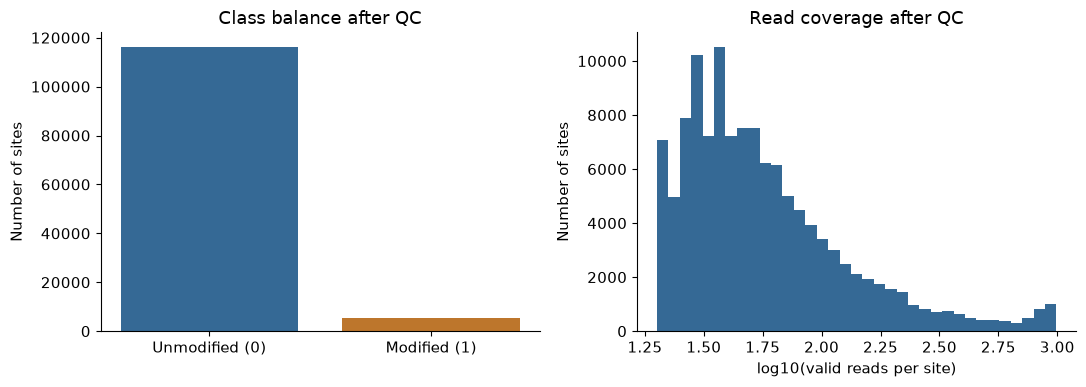

,n_reads_valid
count,121838.000000
mean,90.506295
std,137.333376
min,20.000000
10%,25.000000
25%,32.000000
50%,47.000000
75%,84.000000
90%,175.000000
99%,869.000000


In [16]:
display(joined[['gene_id', 'label'] + FEATURES].isna().mean()
        .sort_values(ascending=False).head(12).rename('missing_fraction_outer_join').to_frame())
before = labels['label'].value_counts().reindex([0,1], fill_value=0)
after = clean_labeled['label'].value_counts().reindex([0,1], fill_value=0)
display(pd.DataFrame({'all_usable_labels': before, 'matched_QC_sites': after}))
if clean_labeled.empty:
    print('No labelled sites survived. Review join diagnostics and input paths before modelling.')
else:
    print(f'Positive fraction: {clean_labeled.label.mean():.2%}')
    fig, axes = plt.subplots(1, 2, figsize=(11,4))
    axes[0].bar(['Unmodified (0)', 'Modified (1)'], after.values, color=['#356995','#bd762c'])
    axes[0].set(ylabel='Number of sites', title='Class balance after QC')
    axes[1].hist(np.log10(clean_labeled.n_reads_valid), bins=35, color='#356995')
    axes[1].set(xlabel='log10(valid reads per site)', ylabel='Number of sites', title='Read coverage after QC')
    fig.tight_layout(); plt.show()
    display(clean_labeled['n_reads_valid'].describe(percentiles=[.1,.25,.5,.75,.9,.99]).to_frame())

### 7. Compare signal distributions and motifs
Box plots show the distribution of **site-level means across reads**; they do not show individual reads. Outliers are hidden only in these plots, not removed. The handout does not specify measurement units, so none are inferred here. Label differences are descriptive and do not establish model performance.

If you plan a strict held-out evaluation, use these all-data plots for structural QC only. Freeze the split before label-guided feature selection, and perform that exploration on training data.

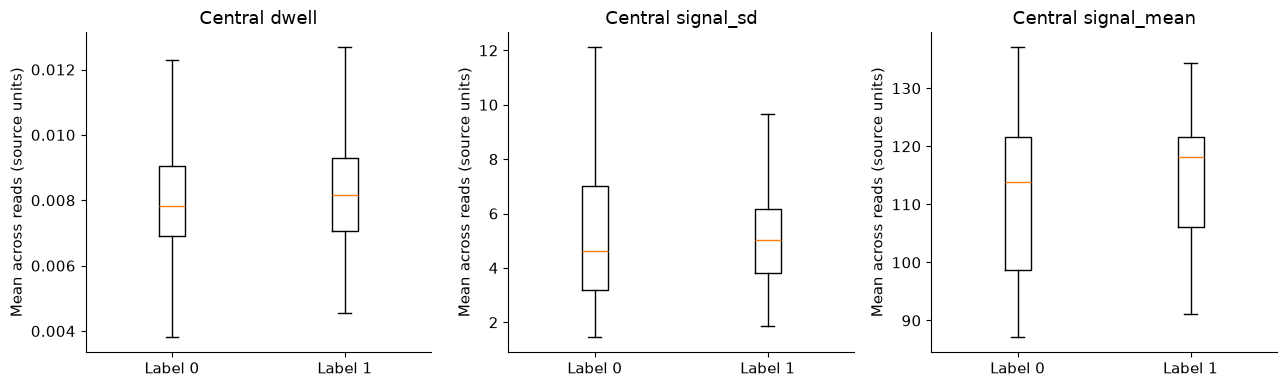

,sites,modified_sites,positive_fraction
central_5mer,,,
AAACA,10152,38,0.003743
AAACT,8627,255,0.029558
GAACA,7934,187,0.023569
GGACA,7727,691,0.089427
TGACA,7718,68,0.008811
AGACA,7396,147,0.019876
GGACC,7353,552,0.075071
TGACC,7304,90,0.012322
GAACT,6957,783,0.112549


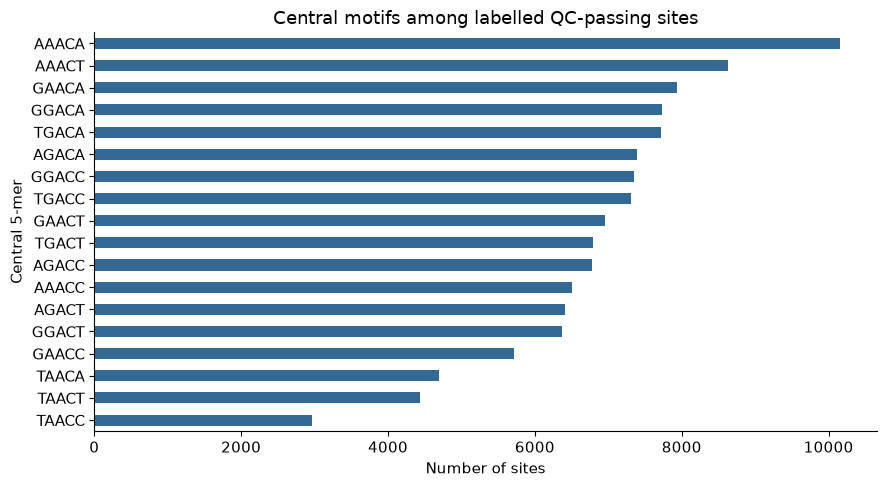

,mean,std,min,max
minus1_dwell_mean,0.008108,0.001787,0.003616,0.019119
minus1_signal_sd_mean,4.342127,1.936267,1.361306,11.644615
minus1_signal_mean_mean,110.789403,11.289521,80.370000,136.285714
center_dwell_mean,0.008127,0.001693,0.003803,0.021581
center_signal_sd_mean,5.157547,2.184069,1.441381,12.128800
center_signal_mean_mean,110.946258,12.460242,87.071498,137.120000
plus1_dwell_mean,0.007057,0.001296,0.003537,0.016344
plus1_signal_sd_mean,2.974051,0.894199,1.350225,11.898750
plus1_signal_mean_mean,86.203293,4.937330,72.231429,105.773134
minus1_dwell_std,0.004887,0.001505,0.000953,0.018516


In [17]:
if not clean_labeled.empty:
    fig, axes = plt.subplots(1, 3, figsize=(13,4))
    for ax, measure in zip(axes, ('dwell','signal_sd','signal_mean')):
        col = f'center_{measure}_mean'
        groups = [clean_labeled.loc[clean_labeled.label.eq(k),col].to_numpy() for k in (0,1)]
        ax.boxplot(groups, showfliers=False)
        ax.set_xticks([1,2], ['Label 0','Label 1'])
        ax.set(title=f'Central {measure}', ylabel='Mean across reads (source units)')
    fig.tight_layout(); plt.show()
    motif_summary = clean_labeled.groupby('central_5mer').agg(
        sites=('label','size'), modified_sites=('label','sum'), positive_fraction=('label','mean'))
    display(motif_summary.sort_values('sites', ascending=False))
    fig, ax = plt.subplots(figsize=(9,5))
    motif_summary.sites.sort_values().plot.barh(ax=ax, color='#356995')
    ax.set(title='Central motifs among labelled QC-passing sites', xlabel='Number of sites', ylabel='Central 5-mer')
    fig.tight_layout(); plt.show()
    display(clean_labeled[FEATURES].describe().T[['mean','std','min','max']].head(12))

### 8. Export tables and reproducibility record
`clean_labeled_sites.csv.gz` is the main tabular training input. `clean_signal_sites.csv.gz` also includes QC-passing sites without labels. Audit files explain exclusions; `feature_columns.json` defines the intended predictors.

The manifest records input paths, sizes, modification times, settings, and package versions. It does not hash the entire large JSON. Keep original files unchanged for reproducibility. No exported table contains fabricated labels.

In [23]:
# 9. Export cleaned datasets and reproducibility record

# Main datasets
clean_labeled.to_csv(
    RUN_DIR / "clean_labeled_sites.csv.gz", index=False
)
clean_sites.to_csv(
    RUN_DIR / "clean_signal_sites.csv.gz", index=False
)

# Audit files
quarantined.to_csv(
    RUN_DIR / "quarantined_sites.csv.gz", index=False
)
bad_label_rows.to_csv(
    RUN_DIR / "invalid_label_rows.csv", index=False
)
conflicting_labels.to_csv(
    RUN_DIR / "conflicting_label_rows.csv", index=False
)
unmatched.to_csv(
    RUN_DIR / "unmatched_sites.csv.gz", index=False
)
join_counts.to_csv(RUN_DIR / "join_counts.csv")

# Define model features here because the splitting section was removed
model_features = FEATURES + ["n_reads_valid", "central_5mer"]

(RUN_DIR / "feature_columns.json").write_text(
    json.dumps(model_features, indent=2),
    encoding="utf-8"
)

# Record settings and cleaning results
manifest = {
    "source_handout": "handout_project2_RNAModifications.html",
    "input_files": [
        {
            "path": str(p.resolve()),
            "bytes": p.stat().st_size,
            "mtime_ns": p.stat().st_mtime_ns
        }
        for p in (DATA_JSON, LABELS_FILE)
    ],
    "max_lines": MAX_LINES,
    "min_valid_reads": MIN_VALID_READS,
    "split_created": False,
    "parse_counts": parse_counts,
    "raw_sites": len(sites),
    "quarantined_sites": len(quarantined),
    "clean_signal_sites": len(clean_sites),
    "clean_labeled_sites": len(clean_labeled),
    "removed_reads": int(sites.n_reads_removed.sum()),
    "invalid_label_rows": len(bad_label_rows),
    "exact_label_duplicates_collapsed": int(n_exact_label_duplicates),
    "conflicting_label_rows": len(conflicting_labels),
    "python": sys.version,
    "platform": platform.platform(),
    "packages": {
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": importlib.import_module("matplotlib").__version__
    },
    "cleaning_policy": (
        "Finite 9-value reads; nonnegative dwell and SD; "
        "strict ACGT seven-mer and DRACH; quarantine duplicate sites; "
        "no clipping/imputation/resampling"
    )
}

(RUN_DIR / "run_manifest.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8"
)

print("Saved outputs to:", RUN_DIR.resolve())
print(f"Clean labelled sites: {len(clean_labeled):,}")
print(f"Model input columns before encoding: {len(model_features)}")

if MAX_LINES is not None:
    print(
        f"Note: only the first {MAX_LINES:,} lines were processed. "
        "Set MAX_LINES = None and rerun to export the full dataset."
    )

display(
    pd.DataFrame({
        "file": [p.name for p in sorted(RUN_DIR.iterdir())]
    })
)

Saved outputs to: D:\NUS\AY2627_Year_4\AY2627_Y4_Sem1\DSA4262_genomics\Assignments\Team_Project\DSA4262-datahelix\data_cleaning\outputs\m6a_eda\20261005T115003_741688Z
Clean labelled sites: 121,838
Model input columns before encoding: 47


,file
0,clean_labeled_sites.csv.gz
1,clean_signal_sites.csv.gz
2,conflicting_label_rows.csv
3,feature_columns.json
4,invalid_label_rows.csv
5,join_counts.csv
6,quarantined_sites.csv.gz
7,run_manifest.json
8,unmatched_sites.csv.gz


## Checks and next steps
- Review `join_counts`, quarantine reasons, removed-read counts and label conflicts. Resolve unexpected data loss before training.
- Run the full file after the prefix check; report actual class counts and coverage from your run.
- Agree on one split file for all four team members so model comparisons use identical partitions.
- For tabular models, reuse **the same feature extraction** in the final training and prediction scripts. Do not train an ordinary classifier on individual reads with copied site labels without justifying that assumption.
- An unseen prediction site may fail QC. Your final prediction script needs an explicit policy that still satisfies the required output keys; this exploration notebook's quarantine table is not a complete prediction submission.
- Evaluate with ROC AUC and precision–recall metrics as required by the handout. State whether you use average precision or trapezoidal PR AUC; they are not interchangeable. Benchmark against a simple baseline and m6Anet with compatible evaluation sets.
- Document AI assistance and verify generated code against the handout. This notebook is AI-assisted; record any errors you actually find and how you fixed them, as required by the project.

**Local validation:** after setting paths, use **Restart Kernel → Run All** in VS Code. Real-data results and rendered plots still require inspection on your machine.